**Setup.** Run this notebook from the `notebooks/` folder of the book
repository (it reads files from `Data/` and `Support/`). On Google Colab,
upload the folder to your Drive and set `path` to its location, e.g.
`path = '/content/drive/MyDrive/StatsBook/notebooks/'`.

In [1]:
path = ''

Filtering an image with the convolution theorem (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $f$, $\hat{f}=\mathcal{F}\{f\}$ | `f`, `f_hat` | image and its 2D FT |
| $g_1$, $g_2$ ($\sigma=1$, $\sigma=10$) | `g1`, `g2` | Gaussian filters (same size as the image) |
| $\hat{f}_i=\hat{f}\cdot\hat{g}_i$ | `f1_hat`, `f2_hat` | filtered images in the frequency domain |
| $f_i=\mathcal{F}^{-1}\{\hat{f}_i\}$ | `f1`, `f2` | filtered images |

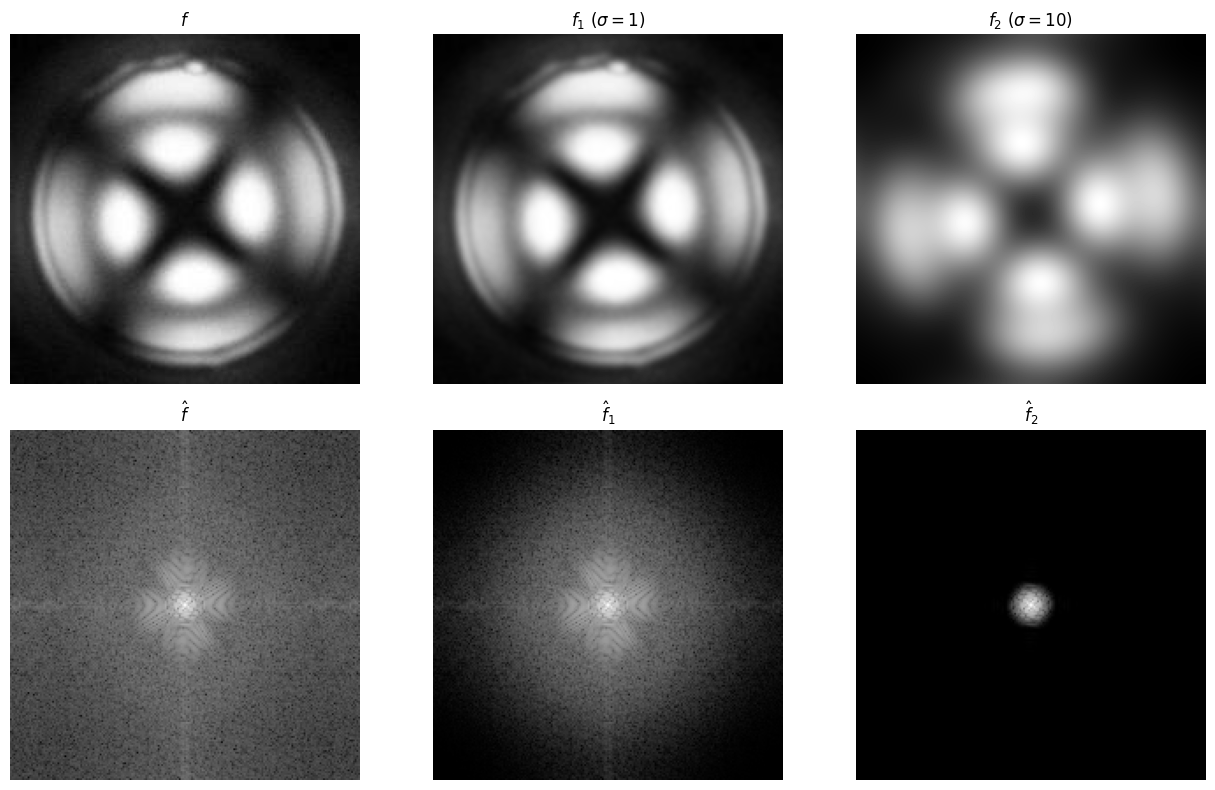

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from scipy.ndimage import gaussian_filter

f = plt.imread(path+'Data/droplet1g.jpg').astype(float)
if f.ndim == 3:
    f = f[..., 0]

def gaussian_kernel(shape, sigma):
    """Gaussian filter g as an image: a centred delta blurred with sigma (unit sum)."""
    g = np.zeros(shape)
    g[shape[0] // 2, shape[1] // 2] = 1.0
    return gaussian_filter(g, sigma=sigma)

f_hat = fft2(f)
results = []
for sigma in (1, 10):
    g = gaussian_kernel(f.shape, sigma)
    g_hat = fft2(ifftshift(g))                 # kernel centred at the origin
    fi_hat = f_hat * g_hat                     # convolution theorem
    fi = np.real(ifft2(fi_hat))
    results.append((sigma, fi, fi_hat))

def spectrum(z_hat):
    return fftshift(np.log(1 + np.abs(z_hat)))

fig, axs = plt.subplots(2, 3, figsize=(13, 8))
axs[0, 0].imshow(f, cmap='gray'); axs[0, 0].set_title('$f$')
axs[1, 0].imshow(spectrum(f_hat), cmap='gray'); axs[1, 0].set_title(r'$\hat{f}$')
for k, (sigma, fi, fi_hat) in enumerate(results, start=1):
    axs[0, k].imshow(fi, cmap='gray'); axs[0, k].set_title(rf'$f_{k}$ ($\sigma={sigma}$)')
    axs[1, k].imshow(spectrum(fi_hat), cmap='gray'); axs[1, k].set_title(rf'$\hat{{f}}_{k}$')
for ax in axs.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

Check: the result equals a direct (spatial) Gaussian convolution.

In [3]:
direct = gaussian_filter(f, sigma=1, mode='wrap')
print(f"max |f_1 (FFT) - f_1 (direct)| = {np.max(np.abs(results[0][1] - direct)):.2e}")

max |f_1 (FFT) - f_1 (direct)| = 4.26e-13
